In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Configure plot styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

#### Load the dataset

In [4]:
df = pd.read_excel('C:\\Users\\saher\\OneDrive\\Documents\\Intership_Projects\\Apple_iPhone_Sales_Analysis\\data\\raw\\iPhone_India_Shipments_2020_2026.xlsx')

In [5]:
print("--- Dataset Head ---")
display(df.head(10))

print("\n--- Dataset Info ---")
df.info()

--- Dataset Head ---


,Year,Country,Brand,Product_Category,Annual_Shipments_Million,Data_Status,Source_Name,Source_Date,YoY Growth %,Absolute Increase,Cumulative Shipments,Overall Growth,Compound Annual Growth Rate,Average Shipments
0,2020,India,Apple,Smartphone,3.2,Estimated,Counterpoint Research (reported by Statista),2021-01-27,NaN,NaN,NaN,NaN,NaN,NaN
1,2021,India,Apple,Smartphone,4.2,Reported estimate,CMR (reported by Business Standard),2022-01-17,31.250000,1.0,3.2,156.25,0.207071,5.7
2,2022,India,Apple,Smartphone,5.2,Reported estimate,IDC (reported by Economic Times),2023-03-21,23.809524,1.0,7.4,-100.00,-1.000000,6.2
3,2023,India,Apple,Smartphone,6.2,Estimated,IDC (reported by Mint),2023-10-31,19.230769,1.0,12.6,-100.00,-1.000000,6.7
4,2024,India,Apple,Smartphone,7.2,Reported estimate,IDC (reported by Indian Express),2025-02-10,16.129032,1.0,18.8,-100.00,-1.000000,7.2
5,2025,India,Apple,Smartphone,8.2,Estimated,Market data reported by TechCrunch,2026-01-23,13.888889,1.0,26.0,-100.00,-1.000000,7.7
6,2026,India,Apple,Smartphone,NaN,Pending full-year data,Not yet verified,NaT,NaN,NaN,NaN,NaN,NaN,NaN



--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Year                         7 non-null      int64         
 1   Country                      7 non-null      str           
 2   Brand                        7 non-null      str           
 3   Product_Category             7 non-null      str           
 4   Annual_Shipments_Million     6 non-null      float64       
 5   Data_Status                  7 non-null      str           
 6   Source_Name                  7 non-null      str           
 7   Source_Date                  6 non-null      datetime64[us]
 8   YoY Growth %                 5 non-null      float64       
 9   Absolute Increase            5 non-null      float64       
 10  Cumulative Shipments         5 non-null      float64       
 11  Overall Growth               5 non-nul

#### Data Cleaning 

##### Check for missing values

In [6]:
print("Missing values per column:\n", df.isnull().sum())

Missing values per column:
 Year                           0
Country                        0
Brand                          0
Product_Category               0
Annual_Shipments_Million       1
Data_Status                    0
Source_Name                    0
Source_Date                    1
YoY Growth %                   2
Absolute Increase              2
Cumulative Shipments           2
Overall Growth                 2
Compound Annual Growth Rate    2
Average Shipments              2
dtype: int64


##### Check for duplicate records

In [7]:
print("\nDuplicate rows count:", df.duplicated().sum())


Duplicate rows count: 0


##### Ensure Year is integer and Annual_Shipments_Million is float

In [8]:
df['Year'] = df['Year'].astype(int)
df['Annual_Shipments_Million'] = pd.to_numeric(df['Annual_Shipments_Million'], errors='coerce')

print("\nData types successfully verified.")


Data types successfully verified.


### Feature Engineering

#### Calculate Year-over-Year Growth Percentage

In [9]:
df['YoY_Growth_Pct'] = df['Annual_Shipments_Million'].pct_change() * 100

#### Calculate Absolute Increase

In [10]:
df['Absolute_Increase_Million'] = df['Annual_Shipments_Million'].diff()

#### Calculate Cumulative Shipments

In [11]:
df['Cumulative_Shipments_Million'] = df['Annual_Shipments_Million'].cumsum()


#### Display processed dataframe

In [12]:
display(df[['Year', 'Annual_Shipments_Million', 'YoY_Growth_Pct', 'Absolute_Increase_Million', 'Cumulative_Shipments_Million']])

,Year,Annual_Shipments_Million,YoY_Growth_Pct,Absolute_Increase_Million,Cumulative_Shipments_Million
0,2020,3.2,NaN,NaN,3.2
1,2021,4.2,31.250000,1.0,7.4
2,2022,5.2,23.809524,1.0,12.6
3,2023,6.2,19.230769,1.0,18.8
4,2024,7.2,16.129032,1.0,26.0
5,2025,8.2,13.888889,1.0,34.2
6,2026,NaN,NaN,NaN,NaN


In [13]:
# Calculate CAGR from 2020 to 2025 (5-year period)
val_2020 = df.loc[df['Year'] == 2020, 'Annual_Shipments_Million'].values[0]
val_2025 = df.loc[df['Year'] == 2025, 'Annual_Shipments_Million'].values[0]
cagr_2020_2025 = (((val_2025 / val_2020) ** (1 / 5)) - 1) * 100

print(f"\nCompound Annual Growth Rate (CAGR 2020–2025): {cagr_2020_2025:.2f}%")


Compound Annual Growth Rate (CAGR 2020–2025): 20.71%


### Exploratory Data Visualization (EDA Charts)

#### 1. Annual iPhone Shipments in India:

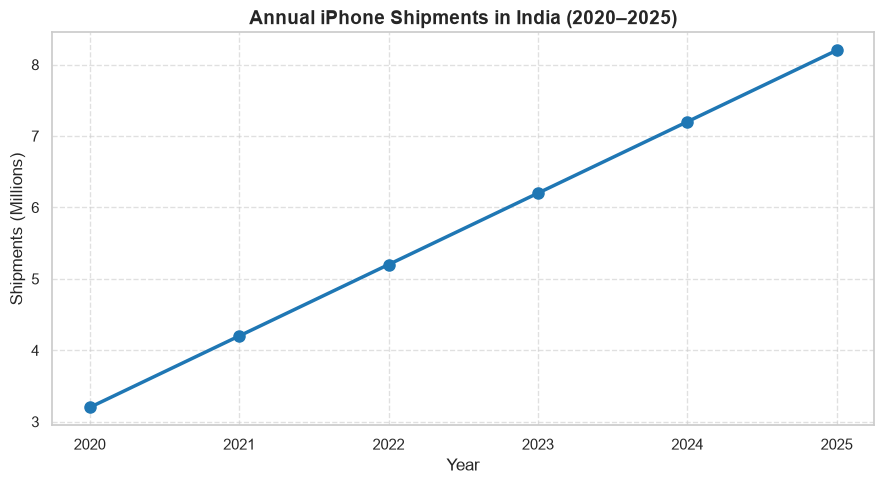

In [14]:
plt.figure(figsize=(9, 5))
historical_df = df.dropna(subset=['Annual_Shipments_Million'])
plt.plot(historical_df['Year'], historical_df['Annual_Shipments_Million'], marker='o', color='#1f77b4', linewidth=2.5, markersize=8)
plt.title('Annual iPhone Shipments in India (2020–2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Shipments (Millions)', fontsize=12)
plt.xticks(historical_df['Year'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### 2. Year-over-Year Shipment Growth (%):

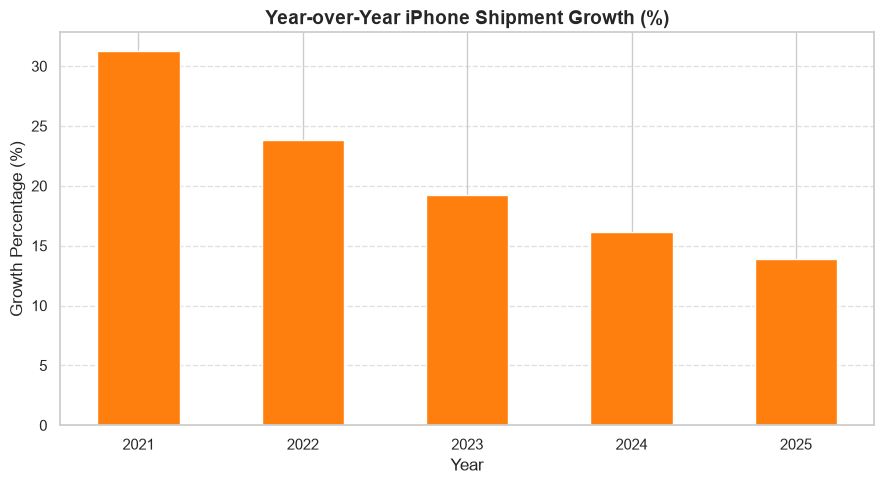

In [15]:
plt.figure(figsize=(9, 5))
growth_df = historical_df.dropna(subset=['YoY_Growth_Pct'])
plt.bar(growth_df['Year'], growth_df['YoY_Growth_Pct'], color='#ff7f0e', width=0.5)
plt.title('Year-over-Year iPhone Shipment Growth (%)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Growth Percentage (%)', fontsize=12)
plt.xticks(growth_df['Year'])
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### 3: Absolute Shipment Increase

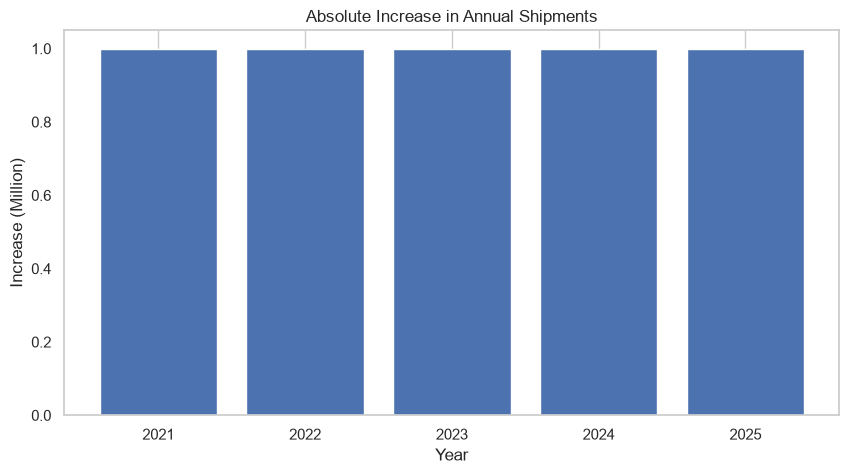

In [16]:
plt.figure(figsize=(10,5))

plt.bar(
    historical_df['Year'],
    historical_df['Absolute_Increase_Million']
)

plt.title('Absolute Increase in Annual Shipments')

plt.xlabel('Year')

plt.ylabel('Increase (Million)')

plt.grid(axis='y')

plt.show()